# ¿Cuánto aviso nos da un río? · 04 — Anticipación de nuevas superaciones del P95

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py`; identificado como `v4` en el código y en las salidas), con verificación por eventos sobre un universo único.

**Lugar en el estudio:** este cuaderno responde la pregunta **P2**: con cuántos días reales se anticipa un nuevo cruce del P95 usando solo el caudal local. Fija las reglas de verificación de avisos que usan después los cuadernos 06, 08 y 09.

**Sobre el periodo de prueba:** las reglas de verificación y de selección se fijaron antes de la evaluación final, pero el periodo de prueba (2016–fin) se consultó durante el desarrollo del proyecto: no es un periodo nunca visto.

---

## 0. Pregunta y protocolo (fijados antes de ver la prueba)

> **¿Con cuántos días reales de anticipación se puede advertir una nueva superación del P95 y con qué detecciones, omisiones, falsas alarmas y errores de fecha?**

En palabras simples: antes de que el río supere un nivel de caudal elevado, ¿el pronóstico puede avisarlo, con cuántos días de anticipación y cuántas veces se equivoca? Los cuadernos 01–02 miden la **magnitud**; este mide la **anticipación de eventos nuevos**. El primer cruce del P95 no es necesariamente el inicio físico de la subida del río ni un desborde, y el P95 es un umbral estadístico, no oficial.

| Elemento | Definición |
|---|---|
| Fenómeno | P95 del caudal observado en el **entrenamiento** de cada estación; "alto" = Q > P95. Tres estados diarios: **alto**, **bajo** y **desconocido** (sin dato). Un vacío nunca cuenta como día bajo. |
| Nuevo cruce elegible | Día d alto cuyos **7 días previos** están observados y bajo el umbral. Los demás cruces se cuentan como identificados pero no elegibles, con su motivo (vacío previo o menos de 7 días bajo desde el evento anterior). |
| Emisión elegible (causal) | Día t con t − 6 … t observados y bajo el umbral: solo usa información disponible en t; nunca agrupa eventos con datos futuros. |
| Aviso | Desde una emisión elegible, alguna salida de la trayectoria **mediana** pronosticada Q̂(t + 1 … t + h_max) (exp del cambio log, sin corrección de Duan: no depende de ningún factor estimado) supera **u = f × P95**. Fecha pronosticada τ = t + primer h con Q̂ > u. El factor f solo cambia la **activación** y absorbe el sesgo de la mediana; el fenómeno sigue siendo P95. |
| Universo verificable U | Nuevos cruces elegibles con una emisión elegible el día anterior, dentro del periodo de emisiones. Es el **mismo conjunto** para POD, FAR y CSI. |
| Aviso correcto | Existe d ∈ U con t < d y \|τ − d\| ≤ 2 días (la tolerancia empareja fechas objetivo; nunca convierte un aviso tardío en uno temprano). Si no es correcto y la ventana τ ± 2 tiene días desconocidos, un cruce no elegible o un cruce elegible fuera de U (por ejemplo, después de la última emisión), es **no verificable** y no entra en ninguna métrica; si no, es **falso**. Un día alto dentro de un evento ya iniciado no vuelve correcto un aviso de inicio. |
| Episodio | Avisos en días de emisión consecutivos, partido cada **7 días** para que un aviso encendido toda la temporada no cuente como uno solo. |
| Emparejamiento | Uno a uno y cronológico: cada episodio se asigna al primer cruce aún libre para el que tiene un aviso correcto (**acierto**); si solo acierta cruces ya emparejados es **repetido** (no suma ni resta); sin avisos correctos es **falsa alarma** (o no verificable). |
| Anticipación **real** | d − fecha de emisión del primer aviso correcto del episodio emparejado (no el horizonte nominal de la salida usada). |
| Métricas (mismos H, M y F) | Con H aciertos, M omisiones y F falsas alarmas del mismo universo: POD = H/(H+M); FAR = F/(H+F); CSI = H/(H+M+F). Sin denominador, la métrica queda **no definida**. El código comprueba en cada evaluación que H es el mismo en las tres. |
| Por anticipación exigida A (sistema completo) | Universo U_A: cruces de U con emisiones elegibles todos los días d − A … d − 1 (se informa N_A). Acierto a A: detectado con anticipación real ≥ A; un aviso **tardío** cuenta como omisión a A. F: todas las falsas alarmas del sistema (no dependen de A). POD(A) = H_A/N_A; CSI(A) = H_A/(N_A + F). La FAR es global. |
| Carga de avisos | Días con aviso, episodios y falsas alarmas **por año calendario** del periodo de emisiones, y la **cobertura** (días con emisión elegible / días del periodo). |
| Anticipación útil (criterio exploratorio fijado de antemano) | Si FAR ≤ 0.5: mayor A consecutivo desde 1 con POD(A) ≥ 0.5. Si FAR > 0.5 o no definida: 0. Que un modelo no lo alcance significa que **no alcanzó este criterio**, no que no tenga ninguna capacidad; estos umbrales tampoco demuestran utilidad operativa para protección civil. |
| Error de fecha | Para la trayectoria del primer aviso correcto, y para las emisiones de 1, 3 y 7 días antes: primer día con Q̂ > **P95** − d (positivo = tarde). Si la trayectoria no cruza el P95, queda no disponible. |
| Calibración (validación 2009–2015) | Por candidato: f ∈ {0.5, 0.6, …, 1.1} × h_max ∈ {3, 7, 15, 30}; se elige el máximo CSI **entre las reglas con FAR ≤ 0.5** (si ninguna lo cumple, el máximo CSI y se marca que no cumple); empates: f más cercano a 1 y luego h_max menor. **Modelo para avisos:** entre los seis modelos, el de mayor CSI calibrado (primero los que cumplen FAR ≤ 0.5); empates: el más simple. Las trayectorias medianas no usan factores, así que toda la validación sirve sin información posterior. |
| Referencias | Persistencia (avisa si hoy ya supera u), climatología del día y **tendencia de 3 días**, con la misma calibración. |
| Sensibilidad | Tolerancia 0, ±1 y ±2 días; partición de episodios cada 3, 7 y 15 días; reinicio de 3, 7 y 14 días. |

**Datos diarios:** la anticipación se mide en días; se supone que el caudal del día t está disponible al emitir. Los 17 casos de verificación del código (aviso previo, aviso tardío, duplicación, huecos, eventos largos, aviso continuo, borde final, emisión faltante, sin eventos, POD sobre un conjunto fijo, fechas duplicadas y coherencia de fórmulas) están en `pruebas_avisos.py` y se ejecutan al inicio.

---
## 1. Configuración, datos y verificación del código

In [1]:
import json, os, subprocess, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import comun as C

%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
RUTA_FIG, RUTA_TAB = C.ruta_salidas() / 'anticipacion' / 'figuras', C.ruta_salidas() / 'anticipacion' / 'tablas'          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)
print(subprocess.run([sys.executable, 'pruebas_avisos.py'], capture_output=True, text=True, check=True).stdout)

EST = ['Racarumi', 'Tamshiyacu']
A = C.AVISO
REFS = ['Persistencia', 'Climatología', 'Tendencia 3 días']
D = {}
for e in EST:
    base = C.ruta_salidas() / e.lower()
    z = np.load(base / 'predicciones.npz', allow_pickle=False)
    res = json.loads((base / 'resumen.json').read_text(encoding='utf-8'))
    C.verificar_resumen(base / 'resumen.json')        # mismo protocolo y mismo modo de ejecución (final o rápido)
    q, _ = C.cargar_serie(e)
    modelos = [str(x) for x in z['modelos']]
    f_v, f_p = pd.to_datetime(z['fechas_val'], unit='D'), pd.to_datetime(z['fechas_pru'], unit='D')
    H = z['obs_pru'].shape[1]
    pv = {n: z[f'valmed_{i}'].astype(float) for i, n in enumerate(modelos)}      # mediana pronosticada, validación
    pp = {n: z[f'prumed_{i}'].astype(float) for i, n in enumerate(modelos)}      # mediana pronosticada, prueba
    pv['Persistencia'], pp['Persistencia'] = z['pers_val'].astype(float), z['pers_pru'].astype(float)
    pv['Climatología'], pp['Climatología'] = z['clim_val'].astype(float), z['clim_pru'].astype(float)
    pv['Tendencia 3 días'], pp['Tendencia 3 días'] = C.pred_tendencia(q, f_v, H, res['eps']), C.pred_tendencia(q, f_p, H, res['eps'])
    D[e] = dict(q=q, P95=res['P95'], f_v=f_v, f_p=f_p, pv=pv, pp=pp, mejor=res['mejor_modelo'], res=res)
CAND = C.MODELOS + REFS
FC = C.fechas_comunes()

OK   aviso previo
OK   anticipación real 1 día
OK   fecha fuera de tolerancia
OK   duplicación
OK   hueco
OK   vacío ≠ bajo
OK   evento largo
OK   día alto no es inicio
OK   aviso continuo
OK   sin avisos
OK   borde final
OK   emisión faltante antes del cruce
OK   sin eventos
OK   aviso tardío a A = 2
OK   POD sobre conjunto fijo
OK   fechas duplicadas
OK   coherencia POD/FAR/CSI
17 casos correctos



In [2]:
filas = []
for e in EST:
    d = D[e]
    for bloque, f_, pr in [('validación', d['f_v'], d['pv'][d['mejor']]), ('prueba', d['f_p'], d['pp'][d['mejor']])]:
        ev = C.evaluar_avisos(f_, pr, d['q'], d['P95'], tol=A['tol'], dmax=A['dmax'], reinicio=A['reinicio'])['eventos']
        filas.append({'estación': e, 'bloque': bloque, 'cruces identificados': len(ev), 'nuevos cruces elegibles': int(ev['elegible'].sum()),
                      'evaluables (emisión elegible el día previo)': int(ev['evaluable'].sum()),
                      'evaluables con ≥ 7 días de emisiones elegibles': int((ev['max_A_evaluable'] >= 7).sum()),
                      'no elegibles: vacío o borde': int((ev['motivo'] == 'vacío o borde antes del cruce').sum()),
                      'no elegibles: evento reciente': int(ev['motivo'].str.startswith('menos').sum())})
cruces_tab = pd.DataFrame(filas).set_index(['estación', 'bloque'])
cruces_tab.to_csv(RUTA_TAB / 'tabla_cruces.csv')
cruces_tab

cruces identificados  nuevos cruces elegibles  \
estación   bloque                                                      
Racarumi   validación                    48                       27   
           prueba                        50                       34   
Tamshiyacu validación                     5                        5   
           prueba                         3                        3   

                       evaluables (emisión elegible el día previo)  \
estación   bloque                                                    
Racarumi   validación                                           27   
           prueba                                               32   
Tamshiyacu validación                                            5   
           prueba                                                3   

                       evaluables con ≥ 7 días de emisiones elegibles  \
estación   bloque                                                       
Racarumi   validación                                              16   
           prueba                                                  24   
Tamshiyacu validación                                               5   
           prueba                                                   3   

                       no elegibles: vacío o borde  \
estación   bloque                                    
Racarumi   validación                            1   
           prueba                                1   
Tamshiyacu validación                            0   
           prueba                                0   

                       no elegibles: evento reciente  
estación   bloque                                     
Racarumi   validación                             20  
           prueba                                 15  
Tamshiyacu validación                              0  
           prueba                                  0

**Interpretación:**
- **Racarumi:** en la prueba hay 50 cruces del P95, de los cuales **34 son nuevos cruces elegibles** (7 días previos observados bajo el umbral) y **32 forman el universo verificable** (con emisión elegible el día anterior); 15 no son elegibles porque ocurren menos de 7 días después de otro evento y 1 por un vacío. Solo 24 permiten evaluar avisos con 7 o más días de anticipación. En validación: 27 evaluables.
- **Tamshiyacu:** 3 cruces en la prueba y 5 en validación, todos elegibles y evaluables. Con 3 eventos cada POD solo puede valer 0, 0.33, 0.67 o 1: sus resultados son **exploratorios**.

---
## 2. Calibración en validación y modelo para avisos
**Calibración de la regla:** para cada estación y candidato se evalúa la malla de f y h_max en validación (pronósticos de modelos entrenados sin esos años) y se elige la combinación de mayor CSI entre las que tienen FAR ≤ 0.5 (regla final de cada candidato). **Modelo para avisos:** se elige con el protocolo común de los cuadernos 04, 06 y 08 (`comun.seleccion_avisos`): la regla de cada modelo se calibra en 2009–2011 y los seis modelos se comparan en 2012–2015 con esa regla (mayor CSI con FAR ≤ 0.5; si empatan, el más simple); el elegido usa luego su regla de toda la validación. Los hiperparámetros de los modelos ya se habían elegido con 2012–2015 para la magnitud: se separan la calibración de la regla y la comparación de candidatos, no todo el procedimiento. Se informa también la elección sin separar (CSI de toda la validación).
**Cuidado:** en validación hay pocos cruces nuevos (sobre todo en Tamshiyacu), así que la calibración es incierta.

In [3]:
def cumple(r):
    return bool(np.isfinite(r['FAR']) and r['FAR'] <= A['far_max'])

def clave(r):
    return (cumple(r), r['CSI'] if np.isfinite(r['CSI']) else -1, -abs(r['f'] - 1), -r['hmax'])

CAL, filas = {}, []
for e in EST:
    d = D[e]
    for n in CAND:
        mejor = None
        for f in A['factores']:
            for hm in A['hmax']:
                r = C.evaluar_avisos(d['f_v'], d['pv'][n], d['q'], d['P95'], f=f, hmax=hm, tol=A['tol'], dmax=A['dmax'], reinicio=A['reinicio'])['resumen']
                fila = {'estación': e, 'modelo': n, **{k: r[k] for k in ['f', 'hmax', 'evaluables', 'aciertos', 'omisiones', 'falsas_alarmas',
                                                                       'repetidos', 'POD', 'FAR', 'CSI', 'dias_aviso_anio']}}
                fila['cumple_FAR'] = cumple(fila)
                filas.append(fila)
                if mejor is None or clave(fila) > clave(mejor):
                    mejor = fila
        CAL[(e, n)] = mejor
cal_tab = pd.DataFrame(filas)
cal_tab.to_csv(RUTA_TAB / 'tabla_calibracion_validacion.csv', index=False)
# Modelo para avisos con el protocolo COMÚN de 04 y 08 (C.seleccion_avisos): la regla de cada modelo se calibra
# en 2009–2011 y los modelos se comparan en 2012–2015 con esa regla; el elegido usa después su regla de toda la validación.
SA = {e: C.seleccion_avisos(D[e]['f_v'], {n: D[e]['pv'][n] for n in C.MODELOS}, D[e]['q'], D[e]['P95'], C.ORDEN_SIMPLICIDAD) for e in EST}
AVISA = {e: SA[e]['elegido'] for e in EST}
for e in EST:
    assert all(SA[e]['regla_final'][n]['f'] == CAL[(e, n)]['f'] and SA[e]['regla_final'][n]['hmax'] == CAL[(e, n)]['hmax'] for n in C.MODELOS)
sel_av = pd.DataFrame([{'estación': e, 'modelo': n, 'regla 2009–2011 (f, h_max)': f"{SA[e]['regla_bloque'][n]['f']}, {SA[e]['regla_bloque'][n]['hmax']}",
                        'cruces 2009–2011': SA[e]['cruces_calibracion'], 'cruces 2012–2015': SA[e]['metricas_seleccion'][n]['evaluables'],
                        'aciertos 2012–2015': SA[e]['metricas_seleccion'][n]['aciertos'], 'falsas alarmas 2012–2015': SA[e]['metricas_seleccion'][n]['falsas_alarmas'],
                        'FAR 2012–2015': SA[e]['metricas_seleccion'][n]['FAR'], 'CSI 2012–2015': SA[e]['metricas_seleccion'][n]['CSI'],
                        'regla final (toda la validación)': f"{CAL[(e, n)]['f']}, {CAL[(e, n)]['hmax']}",
                        'elegido (regla 2009–2011, comparación 2012–2015)': n == SA[e]['elegido'], 'elegido sin separar bloques (CSI de toda la validación)': n == SA[e]['elegido_no_anidado']}
                       for e in EST for n in C.MODELOS]).set_index(['estación', 'modelo'])
sel_av.to_csv(RUTA_TAB / 'tabla_seleccion_avisos.csv')
elegidos = pd.DataFrame([{**CAL[(e, n)], 'modelo para avisos': n == AVISA[e]} for e in EST for n in CAND]).set_index(['estación', 'modelo'])
for e in EST:
    print(f"{e:11s} modelo para avisos (regla en 2009–2011, comparación en 2012–2015 con {SA[e]['cruces_seleccion']} cruces): {AVISA[e]} "
          f"| sin separar bloques: {SA[e]['elegido_no_anidado']} | modelo para magnitud: {D[e]['mejor']}")
display(sel_av.round(3))
elegidos[['f', 'hmax', 'evaluables', 'aciertos', 'falsas_alarmas', 'POD', 'FAR', 'CSI', 'cumple_FAR', 'modelo para avisos']].round(3)

Racarumi    modelo para avisos (regla en 2009–2011, comparación en 2012–2015 con 14 cruces): MLP | sin separar bloques: MLP | modelo para magnitud: LSTM
Tamshiyacu  modelo para avisos (regla en 2009–2011, comparación en 2012–2015 con 3 cruces): KNN | sin separar bloques: KNN | modelo para magnitud: XGBoost


regla 2009–2011 (f, h_max)  cruces 2009–2011  \
estación   modelo                                                          
Racarumi   Regresión lineal                     0.8, 3                13   
           Random Forest                        0.7, 3                13   
           XGBoost                              0.8, 3                13   
           KNN                                  0.8, 3                13   
           MLP                                  0.8, 7                13   
           LSTM                                 0.8, 3                13   
Tamshiyacu Regresión lineal                     1.0, 3                 2   
           Random Forest                        1.0, 3                 2   
           XGBoost                              1.0, 3                 2   
           KNN                                  1.0, 3                 2   
           MLP                                  1.0, 3                 2   
           LSTM                                 1.0, 3                 2   

                             cruces 2012–2015  aciertos 2012–2015  \
estación   modelo                                                   
Racarumi   Regresión lineal                14                   9   
           Random Forest                   14                  11   
           XGBoost                         14                   9   
           KNN                             14                  10   
           MLP                             14                  10   
           LSTM                            14                   8   
Tamshiyacu Regresión lineal                 3                   3   
           Random Forest                    3                   3   
           XGBoost                          3                   3   
           KNN                              3                   3   
           MLP                              3                   3   
           LSTM                             3                   3   

                             falsas alarmas 2012–2015  FAR 2012–2015  \
estación   modelo                                                      
Racarumi   Regresión lineal                         5          0.357   
           Random Forest                            8          0.421   
           XGBoost                                  4          0.308   
           KNN                                      6          0.375   
           MLP                                      4          0.286   
           LSTM                                     5          0.385   
Tamshiyacu Regresión lineal                         3          0.500   
           Random Forest                            1          0.250   
           XGBoost                                  2          0.400   
           KNN                                      1          0.250   
           MLP                                      2          0.400   
           LSTM                                     2          0.400   

                             CSI 2012–2015 regla final (toda la validación)  \
estación   modelo                                                             
Racarumi   Regresión lineal          0.474                           0.8, 3   
           Random Forest             0.500                           0.7, 3   
           XGBoost                   0.500                           0.8, 3   
           KNN                       0.500                           0.8, 3   
           MLP                       0.556                           0.8, 7   
           LSTM                      0.421                           0.8, 3   
Tamshiyacu Regresión lineal          0.500                           1.0, 3   
           Random Forest             0.750                           1.0, 3   
           XGBoost                   0.600                           1.0, 3   
           KNN                       0.750                           1.0, 3   
           MLP                       0.

f  hmax  evaluables  aciertos  falsas_alarmas  \
estación   modelo                                                              
Racarumi   Regresión lineal  0.8     3          27        14              12   
           Random Forest     0.7     3          27        19              18   
           XGBoost           0.8     3          27        15              10   
           KNN               0.8     3          27        17              14   
           MLP               0.8     7          27        17              10   
           LSTM              0.8     3          27        12              10   
           Persistencia      0.8     3          27        14              13   
           Climatología      0.7     3          27         9               3   
           Tendencia 3 días  0.8     3          27        23              56   
Tamshiyacu Regresión lineal  1.0     3           5         5               3   
           Random Forest     1.0     3           5         5               1   
           XGBoost           1.0     3           5         5               2   
           KNN               1.0     3           5         5               1   
           MLP               1.0     3           5         5               2   
           LSTM              1.0     3           5         5               2   
           Persistencia      1.0     3           5         1               0   
           Climatología      0.8     3           5         5              56   
           Tendencia 3 días  1.0     3           5         5               2   

                               POD    FAR    CSI  cumple_FAR  \
estación   modelo                                              
Racarumi   Regresión lineal  0.519  0.462  0.359        True   
           Random Forest     0.704  0.486  0.422        True   
           XGBoost           0.556  0.400  0.405        True   
           KNN               0.630  0.452  0.415        True   
           MLP               0.630  0.370  0.459        True   
           LSTM              0.444  0.455  0.324        True   
           Persistencia      0.519  0.481  0.350        True   
           Climatología      0.333  0.250  0.300        True   
           Tendencia 3 días  0.852  0.709  0.277       False   
Tamshiyacu Regresión lineal  1.000  0.375  0.625        True   
           Random Forest     1.000  0.167  0.833        True   
           XGBoost           1.000  0.286  0.714        True   
           KNN               1.000  0.167  0.833        True   
           MLP               1.000  0.286  0.714        True   
           LSTM              1.000  0.286  0.714        True   
           Persistencia      0.200  0.000  0.200        True   
           Climatología      1.000  0.918  0.082       False   
           Tendencia 3 días  1.000  0.286  0.714        True   

                             modelo para avisos  
estación   modelo                                
Racarumi   Regresión lineal               False  
           Random Forest                  False  
           XGBoost                        False  
           KNN                            False  
           MLP                             True  
           LSTM                           False  
           Persistencia                   False  
           Climatología                   False  
           Tendencia 3 días               False  
Tamshiyacu Regresión lineal               False  
           Random Forest                  False  
           XGBoost                        False  
           KNN                             True  
           MLP                            False  
           LSTM                           False  
           Persistencia                   False  
           Climatología                   False  
           Tendencia 3 días               False

**Interpretación:**
- **Racarumi:** con la trayectoria mediana, la validación elige avisar con **u = 0.8 × P95** en casi todos los modelos (0.7 en Random Forest y la climatología) y **h_max = 3 días** (7 en la MLP): los modelos subestiman las crecidas y solo los primeros días de la trayectoria aportan. **Modelo para avisos: MLP** (CSI de validación 0.46; 17 de 27 cruces con 10 falsas alarmas). Le siguen Random Forest (0.42), KNN (0.42) y XGBoost (0.41). La tendencia de 3 días **no cumple FAR ≤ 0.5** en validación (0.71).
- **Tamshiyacu:** la validación elige **u = P95 y h_max = 3** en todos los modelos. Random Forest y KNN empatan con CSI 0.83 (5 de 5 cruces, 1 falsa alarma); por la regla de empate se toma el más simple, **KNN**. XGBoost, MLP, LSTM y la tendencia llegan a 0.71. Con 5 cruces de validación, esta elección es frágil.
- **El modelo para la magnitud no es el mejor para avisar:** la LSTM (magnitud en Racarumi) queda sexta para avisos; XGBoost (magnitud en Tamshiyacu), detrás de Random Forest y KNN.
- **Selección con bloques separados (protocolo común con los cuadernos 06 y 08):** en Racarumi la regla se calibra con 13 cruces (2009–2011) y los modelos se comparan con 14 (2012–2015); se elige la **MLP** (CSI 0.56 en 2012–2015), la misma que sin separar los bloques. En Tamshiyacu hay 2 y 3 cruces: se elige **KNN** (empata en CSI con Random Forest y es más simple), también la misma. Con tan pocos cruces por bloque la elección es frágil (en Racarumi KNN, Random Forest y XGBoost quedan a 0.06 de CSI): el modelo para avisos debe leerse como uno entre varios que la validación apenas distingue.

---
## 3. Evaluación en prueba
En la prueba (2016–fin) se aplica la regla calibrada de cada candidato y, como comparación, la regla fija u = P95 con h_max = 30: conteos y métricas por eventos, anticipación útil exploratoria, anticipación real mediana y carga de avisos por año calendario (con la cobertura de emisiones elegibles).

In [4]:
RES, filas, filas_A = {}, [], []
for e in EST:
    d = D[e]
    for n in CAND:
        for regla, (f, hm) in [('calibrada', (CAL[(e, n)]['f'], CAL[(e, n)]['hmax'])), ('fija (u = P95, h_max = 30)', (1.0, 30))]:
            out = C.evaluar_avisos(d['f_p'], d['pp'][n], d['q'], d['P95'], f=f, hmax=hm, tol=A['tol'], dmax=A['dmax'], reinicio=A['reinicio'])
            RES[(e, n, regla)] = out
            r = out['resumen']
            filas.append({'estación': e, 'modelo': n, 'regla': regla, 'modelo para avisos': n == AVISA[e], **r})
            filas_A.append(out['por_A'].reset_index().assign(estación=e, modelo=n, regla=regla))
ant = pd.DataFrame(filas)
ant.to_csv(RUTA_TAB / 'tabla_anticipacion_prueba.csv', index=False)
pd.concat(filas_A, ignore_index=True).to_csv(RUTA_TAB / 'tabla_anticipacion_por_A.csv', index=False)
cols = ['f', 'hmax', 'evaluables', 'aciertos', 'omisiones', 'falsas_alarmas', 'repetidos', 'episodios_no_verificables', 'POD', 'FAR', 'CSI',
        'anticipacion_util', 'anticipacion_mediana', 'cobertura', 'episodios_anio', 'falsas_alarmas_anio', 'dias_aviso_anio']
ant[ant['regla'] == 'calibrada'].set_index(['estación', 'modelo'])[cols].round(2)

f  hmax  evaluables  aciertos  omisiones  \
estación   modelo                                                         
Racarumi   Regresión lineal  0.8     3          32         9         23   
           Random Forest     0.7     3          32        16         16   
           XGBoost           0.8     3          32        11         21   
           KNN               0.8     3          32        12         20   
           MLP               0.8     7          32        12         20   
           LSTM              0.8     3          32        10         22   
           Persistencia      0.8     3          32        11         21   
           Climatología      0.7     3          32         9         23   
           Tendencia 3 días  0.8     3          32        23          9   
Tamshiyacu Regresión lineal  1.0     3           3         2          1   
           Random Forest     1.0     3           3         3          0   
           XGBoost           1.0     3           3         3          0   
           KNN               1.0     3           3         3          0   
           MLP               1.0     3           3         3          0   
           LSTM              1.0     3           3         3          0   
           Persistencia      1.0     3           3         0          3   
           Climatología      0.8     3           3         3          0   
           Tendencia 3 días  1.0     3           3         3          0   

                             falsas_alarmas  repetidos  \
estación   modelo                                        
Racarumi   Regresión lineal              15          0   
           Random Forest                 24          2   
           XGBoost                       12          1   
           KNN                           17          2   
           MLP                           14          1   
           LSTM                          12          0   
           Persistencia                  19          0   
           Climatología                   9          4   
           Tendencia 3 días              56          3   
Tamshiyacu Regresión lineal               0          0   
           Random Forest                  0          2   
           XGBoost                        0          1   
           KNN                            0          0   
           MLP                            1          2   
           LSTM                           0          0   
           Persistencia                   0          0   
           Climatología                 114          1   
           Tendencia 3 días               0          1   

                             episodios_no_verificables   POD   FAR   CSI  \
estación   modelo                                                          
Racarumi   Regresión lineal                          0  0.28  0.62  0.19   
           Random Forest                             0  0.50  0.60  0.29   
           XGBoost                                   0  0.34  0.52  0.25   
           KNN                                       0  0.38  0.59  0.24   
           MLP                                       0  0.38  0.54  0.26   
           LSTM                                      0  0.31  0.55  0.23   
           Persistencia                              0  0.34  0.63  0.22   
           Climatología                              0  0.28  0.50  0.22   
           Tendencia 3 días                          0  0.72  0.71  0.26   
Tamshiyacu Regresión lineal                          0  0.67  0.00  0.67   
           Random Forest                             0  1.00  0.00  1.00   
           XGBoost                                   0  1.00  0.00  1.00   
           KNN                                       0  1.00  0.00  1.00   
           MLP                                       0  1.00  0.25  0.75   
           LSTM                                      0  1.00  0.00  1.00   
           Persistencia                              0  0.00   NaN  0.00   
 

In [5]:
ant[(ant['regla'] != 'calibrada') & ant['modelo'].isin(C.MODELOS)].set_index(['estación', 'modelo'])[cols].round(2)

f  hmax  evaluables  aciertos  omisiones  \
estación   modelo                                                         
Racarumi   Regresión lineal  1.0    30          32         2         30   
           Random Forest     1.0    30          32         2         30   
           XGBoost           1.0    30          32         4         28   
           KNN               1.0    30          32         2         30   
           MLP               1.0    30          32         4         28   
           LSTM              1.0    30          32         0         32   
Tamshiyacu Regresión lineal  1.0    30           3         2          1   
           Random Forest     1.0    30           3         3          0   
           XGBoost           1.0    30           3         3          0   
           KNN               1.0    30           3         3          0   
           MLP               1.0    30           3         3          0   
           LSTM              1.0    30           3         3          0   

                             falsas_alarmas  repetidos  \
estación   modelo                                        
Racarumi   Regresión lineal               0          0   
           Random Forest                  1          0   
           XGBoost                        1          1   
           KNN                            1          0   
           MLP                            1          0   
           LSTM                           0          0   
Tamshiyacu Regresión lineal              15          0   
           Random Forest                 14          6   
           XGBoost                       11          6   
           KNN                           10          8   
           MLP                           10          6   
           LSTM                           1          2   

                             episodios_no_verificables   POD   FAR   CSI  \
estación   modelo                                                          
Racarumi   Regresión lineal                          0  0.06  0.00  0.06   
           Random Forest                             0  0.06  0.33  0.06   
           XGBoost                                   0  0.12  0.20  0.12   
           KNN                                       0  0.06  0.33  0.06   
           MLP                                       0  0.12  0.20  0.12   
           LSTM                                      0  0.00   NaN  0.00   
Tamshiyacu Regresión lineal                          0  0.67  0.88  0.11   
           Random Forest                             0  1.00  0.82  0.18   
           XGBoost                                   0  1.00  0.79  0.21   
           KNN                                       1  1.00  0.77  0.23   
           MLP                                       0  1.00  0.77  0.23   
           LSTM                                      0  1.00  0.25  0.75   

                             anticipacion_util  anticipacion_mediana  \
estación   modelo                                                      
Racarumi   Regresión lineal                  0                   1.0   
           Random Forest                     0                   2.5   
           XGBoost                           0                   1.5   
           KNN                               0                   1.0   
           MLP                               0                   1.0   
           LSTM                              0                   NaN   
Tamshiyacu Regresión lineal                  0                   2.5   
           Random Forest                     0                  16.0   
           XGBoost                           0                  10.0   
           KNN                               0                  19.0   
           MLP                               0                  20.0   
           LSTM                              4                   4.0   

                             cobertura  episodios_anio  falsas_alarmas_anio  \
estación   mod

In [6]:
# Indicadores por anticipación exigida A del modelo para avisos (sistema completo: F no depende de A)
pd.concat({e: RES[(e, AVISA[e], 'calibrada')]['por_A'].loc[[1, 2, 3, 5, 7, 10]] for e in EST}, names=['estación', 'A']).round(2)

evaluables  aciertos  aciertos_tardios  omisiones  \
estación   A                                                       
Racarumi   1           32        12                 0         20   
           2           30         7                 4         23   
           3           29         3                 7         26   
           5           26         2                 7         24   
           7           24         1                 7         23   
           10          16         0                 4         16   
Tamshiyacu 1            3         3                 0          0   
           2            3         3                 0          0   
           3            3         3                 0          0   
           5            3         0                 3          3   
           7            3         0                 3          3   
           10           3         0                 3          3   

               falsas_alarmas   POD   CSI  no_evaluables_a_A  \
estación   A                                                   
Racarumi   1               14  0.38  0.26                  0   
           2               14  0.23  0.16                  2   
           3               14  0.10  0.07                  3   
           5               14  0.08  0.05                  6   
           7               14  0.04  0.03                  8   
           10              14  0.00  0.00                 16   
Tamshiyacu 1                0  1.00  1.00                  0   
           2                0  1.00  1.00                  0   
           3                0  1.00  1.00                  0   
           5                0  0.00  0.00                  0   
           7                0  0.00  0.00                  0   
           10               0  0.00  0.00                  0   

               POD_conjunto_fijo  
estación   A                      
Racarumi   1                0.38  
           2                0.22  
           3                0.09  
           5                0.06  
           7                0.03  
           10               0.00  
Tamshiyacu 1                1.00  
           2                1.00  
           3                1.00  
           5                0.00  
           7                0.00  
           10               0.00

In [7]:
# Denominador de POD(A): N_A = cruces evaluables a A (con emisiones elegibles los A días previos).
# Al subir A, N_A puede bajar, así que POD(A) y la anticipación mediana pueden resumir conjuntos distintos de cruces.
# POD_conjunto_fijo = H_A / N_1: divide siempre entre los mismos cruces del universo U (un cruce sin emisiones suficientes
# cuenta como no anticipado a A); es una cota inferior de sensibilidad y no reemplaza al indicador principal.
pd.concat({e: RES[(e, AVISA[e], 'calibrada')]['por_A'].loc[[1, 2, 3, 5, 7, 10], ['evaluables', 'no_evaluables_a_A', 'aciertos', 'POD',
                                                                              'POD_conjunto_fijo']] for e in EST}, names=['estación', 'A']).round(2)

evaluables  no_evaluables_a_A  aciertos   POD  \
estación   A                                                   
Racarumi   1           32                  0        12  0.38   
           2           30                  2         7  0.23   
           3           29                  3         3  0.10   
           5           26                  6         2  0.08   
           7           24                  8         1  0.04   
           10          16                 16         0  0.00   
Tamshiyacu 1            3                  0         3  1.00   
           2            3                  0         3  1.00   
           3            3                  0         3  1.00   
           5            3                  0         0  0.00   
           7            3                  0         0  0.00   
           10           3                  0         0  0.00   

               POD_conjunto_fijo  
estación   A                      
Racarumi   1                0.38  
           2                0.22  
           3                0.09  
           5                0.06  
           7                0.03  
           10               0.00  
Tamshiyacu 1                1.00  
           2                1.00  
           3                1.00  
           5                0.00  
           7                0.00  
           10               0.00

**Interpretación (denominador de POD(A)):**
- **Racarumi:** el universo baja de **32 cruces evaluables a 1 día a 24 a 7 días y 16 a 10 días**: la mitad de los cruces no tiene emisiones elegibles 10 días antes (por eventos recientes o vacíos en la temporada de lluvias). Por eso POD(A) y la anticipación mediana pueden resumir conjuntos distintos de cruces.
- Con la MLP la conclusión no cambia con ningún denominador: POD de 0.38 a 1 día y de 0.04 (1 de 24) a 7 días; sobre el conjunto fijo de 32 cruces, 0.38 y 0.03.
- **Tamshiyacu:** los 3 cruces son evaluables hasta 10 días; KNN los anticipa con 3 días. Con 3 eventos esto es descriptivo.
- La FAR del criterio de anticipación útil es la **global** del sistema (las falsas alarmas no dependen de A).

**Interpretación:**
- **Racarumi: ningún modelo alcanzó el criterio predefinido de anticipación útil** (POD ≥ 0.5 con FAR ≤ 0.5). La MLP avisa **12 de 32 cruces** con 14 falsas alarmas (POD 0.38, FAR 0.54, CSI 0.26); la anticipación real mediana es de **2 días**. El que más se acerca es Random Forest (16 de 32, POD 0.50, pero FAR 0.60).
- **Racarumi frente a las referencias:** la tendencia de 3 días tiene el mismo CSI (0.26) con otro reparto (23 aciertos y 56 falsas alarmas); persistencia y climatología, 0.22 (11 aciertos y 19 falsas alarmas; 9 y 9). Los modelos tienen CSI de 0.19 a 0.29: **no se demostró una mejora consistente** sobre las referencias, aunque varios modelos tengan valores algo mayores. Con la regla fija u = P95, los modelos avisan solo 0–4 de 32 cruces porque su mediana casi nunca alcanza el P95.
- **Tamshiyacu: KNN avisa los 3 cruces sin falsas alarmas**, con 3, 3 y 4 días reales de anticipación (**anticipación útil exploratoria de 3 días**). Random Forest y la tendencia de 3 días llegan a 4 días, XGBoost a 3, la LSTM a 2 y la MLP a 5 días con 1 falsa alarma. **La tendencia de 3 días logra lo mismo que los modelos.**
- **Ventanas largas = más anticipación y muchas más falsas alarmas:** con u = P95 y h_max = 30, Random Forest, XGBoost, KNN y la MLP de Tamshiyacu avisan los 3 cruces con 10–20 días de anticipación real mediana, pero con 10–14 falsas alarmas (FAR 0.77–0.82); la regresión lineal avisa 2 de 3 con 15 falsas alarmas y la LSTM 3 de 3 con 1 falsa alarma y 4 días.
- **Carga de avisos (por año calendario):** la MLP de Racarumi enciende avisos ≈ 6 días por año, con ≈ 1.8 falsas alarmas por año (cobertura de emisiones elegibles: 76 % de los días); KNN en Tamshiyacu, ≈ 1 día por año y ninguna falsa alarma.

**Figura 1.** POD(A) y CSI(A) según la anticipación real exigida A (regla calibrada, sistema completo): modelo para avisos, modelo seleccionado para la magnitud y referencias. En la leyenda, la FAR del sistema (no depende de A); en el título, los cruces evaluables a A = 1.

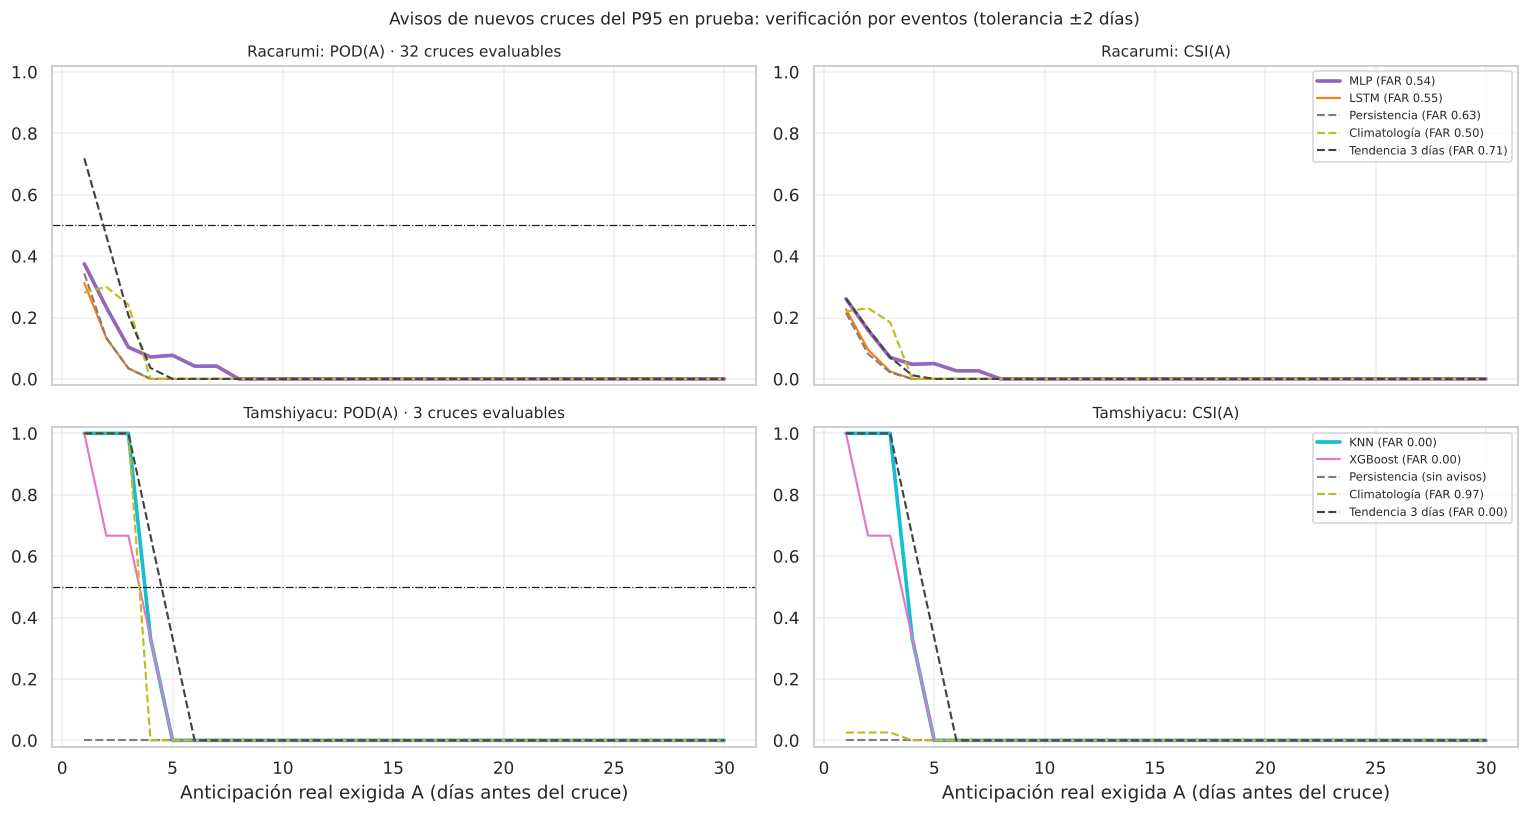

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
for i, e in enumerate(EST):
    d = D[e]
    series = list(dict.fromkeys([AVISA[e], d['mejor']])) + REFS
    for n in series:
        out = RES[(e, n, 'calibrada')]
        pa, far = out['por_A'], out['resumen']['FAR']
        lw = 2.4 if n == AVISA[e] else 1.4
        ls = '-' if n in C.MODELOS else '--'
        et = f"{n} (FAR {far:.2f})" if np.isfinite(far) else f'{n} (sin avisos)'
        ax[i, 0].plot(pa.index, pa['POD'], color=C.COLOR[n], lw=lw, ls=ls, label=et)
        ax[i, 1].plot(pa.index, pa['CSI'], color=C.COLOR[n], lw=lw, ls=ls, label=et)
    n_ev = RES[(e, AVISA[e], 'calibrada')]['resumen']['evaluables']
    ax[i, 0].set_title(f'{e}: POD(A) · {n_ev} cruces evaluables', fontsize=10); ax[i, 1].set_title(f'{e}: CSI(A)', fontsize=10)
    ax[i, 0].axhline(0.5, color='k', lw=0.8, ls='-.')
    for a in ax[i]:
        a.set_ylim(-0.02, 1.02); a.grid(True, alpha=0.3)
    ax[i, 1].legend(fontsize=7.5, loc='upper right')
for a in ax[1]:
    a.set_xlabel('Anticipación real exigida A (días antes del cruce)')
fig.suptitle('Avisos de nuevos cruces del P95 en prueba: verificación por eventos (tolerancia ±2 días)', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_pod_csi_anticipacion.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación (sistema completo: un aviso tardío cuenta como omisión a A; F no depende de A):**
- **Racarumi (arriba):** la MLP detecta 12 de 32 cruces a A = 1, 7 de 30 a A = 2, 3 de 29 a A = 3 y 1 de 24 a A = 7. La tendencia de 3 días detecta más a 1–2 días (23 y 14), con muchas más falsas alarmas. Ninguna curva supera 0.5 desde los 2 días.
- **Tamshiyacu (abajo):** KNN y la tendencia detectan los 3 cruces con hasta 3 días de anticipación; a 4 días, 1 y 2 de 3; ninguno a 6 días o más. La climatología detecta todo con FAR 0.97.

---
## 4. Catálogo por evento, episodios y avisos
Con el modelo para avisos de cada estación, cada cruce del periodo de prueba (elegible o no, con su motivo): si fue detectado, su anticipación real y los errores de fecha. Se guarda además el catálogo de episodios y de avisos diarios con su clasificación.

In [9]:
filas_ev, filas_ep, filas_av = [], [], []
for e in EST:
    out = RES[(e, AVISA[e], 'calibrada')]
    ev = out['eventos'].copy()
    ev['pico 15 d (m³/s)'] = [float(D[e]['q'].loc[f:f + pd.Timedelta(days=14)].max()) for f in ev['fecha']]
    filas_ev.append(ev.assign(estación=e, modelo=AVISA[e]))
    filas_ep.append(out['episodios'].assign(estación=e, modelo=AVISA[e]))
    av = out['avisos'].copy(); av['cruces'] = av['cruces'].astype(str)
    filas_av.append(av.assign(estación=e, modelo=AVISA[e]))
por_evento = pd.concat(filas_ev, ignore_index=True)
por_evento.to_csv(RUTA_TAB / 'tabla_anticipacion_por_evento.csv', index=False)
pd.concat(filas_ep, ignore_index=True).to_csv(RUTA_TAB / 'tabla_episodios.csv', index=False)
pd.concat(filas_av, ignore_index=True).to_csv(RUTA_TAB / 'tabla_avisos.csv', index=False)
ok = por_evento[por_evento['evaluable']]
resumen_ev = ok.groupby('estación').agg(modelo=('modelo', 'first'), evaluables=('fecha', 'count'), detectados=('detectado', 'sum'),
                                        anticipacion_p25=('anticipacion_real', lambda s: s.quantile(0.25)),
                                        anticipacion_mediana=('anticipacion_real', 'median'),
                                        anticipacion_p75=('anticipacion_real', lambda s: s.quantile(0.75)),
                                        error_fecha_umbral_mediano=('error_fecha_umbral', 'median'),
                                        error_A1=('error_fecha_A1', 'median'), error_A3=('error_fecha_A3', 'median'), error_A7=('error_fecha_A7', 'median'),
                                        sin_cruce_del_P95_A3=('error_fecha_A3', lambda s: int(s.isna().sum())))
resumen_ev.round(1)

,modelo,evaluables,detectados,anticipacion_p25,anticipacion_mediana,anticipacion_p75,error_fecha_umbral_mediano,error_A1,error_A3,error_A7,sin_cruce_del_P95_A3
estación,,,,,,,,,,,
Racarumi,MLP,32,12,1.0,2.0,2.2,0.0,0.0,NaN,7.0,32
Tamshiyacu,KNN,3,3,3.0,3.0,3.5,0.0,0.0,0.0,0.0,0


In [10]:
por_evento[['estación', 'fecha', 'elegible', 'motivo', 'evaluable', 'max_A_evaluable', 'detectado', 'anticipacion_real',
            'error_fecha_umbral', 'error_fecha_A1', 'error_fecha_A3', 'error_fecha_A7', 'pico 15 d (m³/s)']].round(1)

,estación,fecha,elegible,motivo,evaluable,max_A_evaluable,detectado,anticipacion_real,error_fecha_umbral,error_fecha_A1,error_fecha_A3,error_fecha_A7,pico 15 d (m³/s)
0,Racarumi,2016-02-25,True,,True,30,False,NaN,NaN,NaN,NaN,NaN,235.7
1,Racarumi,2016-02-27,False,menos de 7 días bajo el umbral desde el evento...,False,0,False,NaN,NaN,NaN,NaN,NaN,235.7
2,Racarumi,2016-03-03,False,menos de 7 días bajo el umbral desde el evento...,False,0,False,NaN,NaN,NaN,NaN,NaN,235.7
3,Racarumi,2016-03-30,True,,True,14,False,NaN,NaN,NaN,NaN,NaN,253.4
4,Racarumi,2016-04-03,False,menos de 7 días bajo el umbral desde el evento...,False,0,False,NaN,NaN,NaN,NaN,NaN,253.4
5,Racarumi,2017-02-11,True,,True,30,True,2.0,NaN,NaN,NaN,NaN,114.4
6,Racarumi,2017-03-08,True,,True,18,True,1.0,0.0,0.0,NaN,NaN,308.6
7,Racarumi,2017-03-22,False,menos de 7 días bajo el umbral desde el evento...,False,0,False,NaN,NaN,NaN,NaN,NaN,275.0
8,Racarumi,2017-05-07,True,,True,27,False,NaN,NaN,NaN,NaN,NaN,132.8
9,Racarumi,2017-05-23,True,,True,9,False,NaN,NaN,NaN,NaN,NaN,120.4


**Interpretación:**
- **Racarumi (MLP):** los 12 cruces detectados se avisaron con 1 a 7 días reales de anticipación (mediana 2; cinco con 1 día). Los avisos se activan con 0.8 × P95: solo 4 de las 12 trayectorias que acertaron llegan a pronosticar el P95, y **desde 3 días antes ninguna trayectoria mediana alcanza el P95** en ningún cruce evaluable (desde 7 días, 1 de 32). El modelo anuncia "caudal alto", no la magnitud del cruce.
- **Tamshiyacu (KNN):** los cruces de 2019, 2022 y 2025 se avisaron con 4, 3 y 3 días; el cruce del P95 pronosticado llegó 1 día antes, el mismo día y el mismo día que lo observado. Desde 1, 3 y 7 días antes los errores de fecha van de −1 a +9 días (el +9 es 2019 desde 7 días antes).

**Figura 2.** (a, b) Diagrama de desempeño con unidades de eventos (POD frente a 1 − FAR; curvas grises: niveles de CSI; lo ideal es la esquina superior derecha), regla calibrada; (c) anticipación real de los cruces detectados por el modelo para avisos.

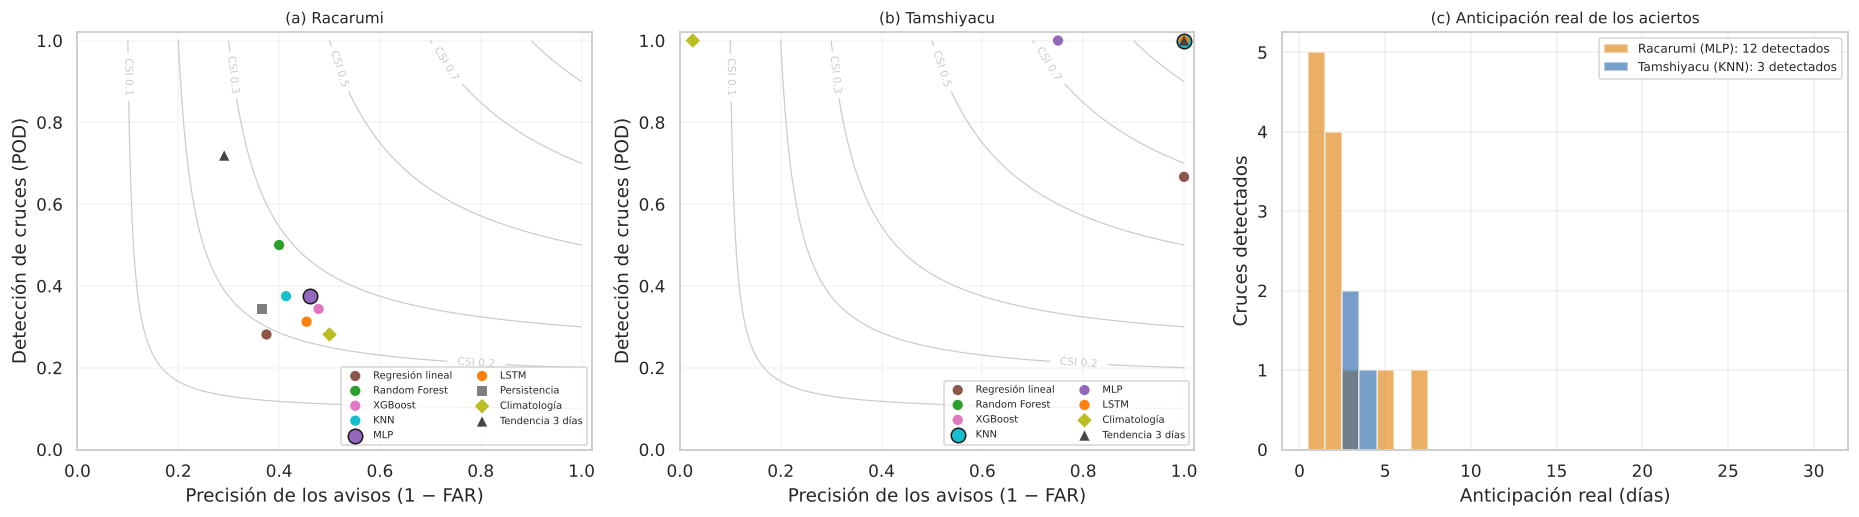

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.1]})
sr, pd_ = np.meshgrid(np.linspace(0.01, 1, 200), np.linspace(0.01, 1, 200))
csi_m = 1 / (1 / sr + 1 / pd_ - 1)          # con aciertos, omisiones y falsas alarmas en las mismas unidades
for a, e in zip(ax[:2], EST):
    cs = a.contour(sr, pd_, csi_m, levels=[0.1, 0.2, 0.3, 0.5, 0.7, 0.9], colors='#cccccc', linewidths=0.8)
    a.clabel(cs, fmt='CSI %.1f', fontsize=7)
    for n in CAND:
        r = RES[(e, n, 'calibrada')]['resumen']
        if not (np.isfinite(r['POD']) and np.isfinite(r['FAR'])):
            continue
        mk = 'o' if n in C.MODELOS else ('s' if n == 'Persistencia' else 'D' if n == 'Climatología' else '^')
        a.scatter(1 - r['FAR'], r['POD'], color=C.COLOR[n], marker=mk, s=90 if n == AVISA[e] else 45, edgecolor='k' if n == AVISA[e] else 'none',
                  zorder=3, label=n)
    a.set_xlim(0, 1.02); a.set_ylim(0, 1.02); a.set_xlabel('Precisión de los avisos (1 − FAR)'); a.set_ylabel('Detección de cruces (POD)')
    a.set_title(f"({'ab'[EST.index(e)]}) {e}", fontsize=10); a.legend(fontsize=6.5, loc='lower right', ncol=2); a.grid(True, alpha=0.2)
for e in EST:
    s = por_evento[(por_evento['estación'] == e) & por_evento['evaluable'] & por_evento['detectado']]['anticipacion_real']
    if len(s):
        ax[2].hist(s, bins=np.arange(0.5, 31.5, 1), alpha=0.6, color={'Racarumi': '#e07b00', 'Tamshiyacu': '#1f5fa8'}[e],
                   label=f"{e} ({AVISA[e]}): {len(s)} detectados")
ax[2].set_xlabel('Anticipación real (días)'); ax[2].set_ylabel('Cruces detectados'); ax[2].legend(fontsize=8); ax[2].grid(True, alpha=0.3)
ax[2].set_title('(c) Anticipación real de los aciertos', fontsize=10)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_desempeno_eventos.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a) Racarumi:** todos los modelos y referencias quedan entre las curvas de CSI 0.2 y 0.3: los que detectan más (la tendencia, POD 0.72) lo pagan con una precisión de ≈ 0.3; la MLP tiene una precisión de 0.46 con POD 0.38.
- **(b) Tamshiyacu:** KNN, Random Forest, XGBoost, la LSTM y la tendencia coinciden en la esquina ideal (POD 1, sin falsas alarmas) con solo 3 cruces; la MLP tiene precisión 0.75, la regresión lineal POD 0.67 y la climatología ≈ 0.03.
- **(c)** La anticipación real de los aciertos es de 1–2 días en la mayoría de los cruces de Racarumi y de 3–4 días en Tamshiyacu.

---
## 5. Sensibilidad a las reglas de verificación
Con el modelo para avisos y su regla calibrada se cambia una regla a la vez en la prueba: tolerancia de fecha (0, ±1, ±2 días), partición de episodios (3, 7, 15 días) y días de reinicio (3, 7, 14).

In [12]:
filas = []
for e in EST:
    d, n = D[e], AVISA[e]
    f, hm = CAL[(e, n)]['f'], CAL[(e, n)]['hmax']
    for nombre_v, kw in [('tolerancia 0', dict(tol=0)), ('tolerancia ±1', dict(tol=1)), ('principal (±2, 7, 7)', {}),
                         ('episodios cada 3 d', dict(dmax=3)), ('episodios cada 15 d', dict(dmax=15)),
                         ('reinicio 3 d', dict(reinicio=3)), ('reinicio 14 d', dict(reinicio=14))]:
        par = {'tol': A['tol'], 'dmax': A['dmax'], 'reinicio': A['reinicio'], **kw}
        r = C.evaluar_avisos(d['f_p'], d['pp'][n], d['q'], d['P95'], f=f, hmax=hm, **par)['resumen']
        filas.append({'estación': e, 'modelo': n, 'variante': nombre_v, **{k: r[k] for k in ['evaluables', 'aciertos', 'omisiones', 'falsas_alarmas',
                                                                                           'repetidos', 'POD', 'FAR', 'CSI', 'anticipacion_util', 'anticipacion_mediana']}})
sens = pd.DataFrame(filas).set_index(['estación', 'variante'])
sens.to_csv(RUTA_TAB / 'tabla_sensibilidad_avisos.csv')
sens.round(2)

modelo  evaluables  aciertos  omisiones  \
estación   variante                                                       
Racarumi   tolerancia 0            MLP          32         8         24   
           tolerancia ±1           MLP          32        11         21   
           principal (±2, 7, 7)    MLP          32        12         20   
           episodios cada 3 d      MLP          32        12         20   
           episodios cada 15 d     MLP          32        12         20   
           reinicio 3 d            MLP          38        19         19   
           reinicio 14 d           MLP          24         7         17   
Tamshiyacu tolerancia 0            KNN           3         2          1   
           tolerancia ±1           KNN           3         3          0   
           principal (±2, 7, 7)    KNN           3         3          0   
           episodios cada 3 d      KNN           3         3          0   
           episodios cada 15 d     KNN           3         3          0   
           reinicio 3 d            KNN           3         3          0   
           reinicio 14 d           KNN           3         3          0   

                                 falsas_alarmas  repetidos   POD   FAR   CSI  \
estación   variante                                                            
Racarumi   tolerancia 0                      18          0  0.25  0.69  0.16   
           tolerancia ±1                     14          1  0.34  0.56  0.24   
           principal (±2, 7, 7)              14          1  0.38  0.54  0.26   
           episodios cada 3 d                17          1  0.38  0.59  0.24   
           episodios cada 15 d               14          1  0.38  0.54  0.26   
           reinicio 3 d                      27          1  0.50  0.59  0.29   
           reinicio 14 d                      8          0  0.29  0.53  0.22   
Tamshiyacu tolerancia 0                       1          0  0.67  0.33  0.50   
           tolerancia ±1                      0          0  1.00  0.00  1.00   
           principal (±2, 7, 7)               0          0  1.00  0.00  1.00   
           episodios cada 3 d                 0          1  1.00  0.00  1.00   
           episodios cada 15 d                0          0  1.00  0.00  1.00   
           reinicio 3 d                       0          0  1.00  0.00  1.00   
           reinicio 14 d                      0          0  1.00  0.00  1.00   

                                 anticipacion_util  anticipacion_mediana  
estación   variante                                                       
Racarumi   tolerancia 0                          0                   1.0  
           tolerancia ±1                         0                   2.0  
           principal (±2, 7, 7)                  0                   2.0  
           episodios cada 3 d                    0                   2.0  
           episodios cada 15 d                   0                   2.0  
           reinicio 3 d                          0                   2.0  
           reinicio 14 d                         0                   1.0  
Tamshiyacu tolerancia 0                          3                   3.0  
           tolerancia ±1                         3                   3.0  
           principal (±2, 7, 7)                  3                   3.0  
           episodios cada 3 d                    3                   3.0  
           episodios cada 15 d                   3                   3.0  
           reinicio 3 d                          3                   3.0  
           reinicio 14 d                         3                   3.0

**Interpretación:**
- **Racarumi:** con tolerancia 0 la MLP baja a 8 aciertos y CSI 0.16; con ±1, a 11 aciertos y CSI 0.24. Partir episodios cada 3 días sube las falsas alarmas a 17; cada 15 días no cambia el resultado. Con un reinicio de 3 días hay 38 cruces evaluables y POD 0.50, pero FAR 0.59; con 14 días, 24 cruces y CSI 0.22. **En ninguna variante se alcanza el criterio de anticipación útil.**
- **Tamshiyacu:** con tolerancia 0, KNN acierta 2 de 3 cruces con 1 falsa alarma, pero la anticipación útil sigue en 3 días; las demás variantes no cambian el resultado.
- **Lectura:** en Racarumi la conclusión no depende de las reglas de verificación; en Tamshiyacu tampoco cambia la cifra, pero descansa en 3 cruces.

---
## 6. Fechas comunes de las dos estaciones
La evaluación de prueba se repite solo con las emisiones de la intersección de fechas (la misma del cuaderno 03). No se exige que los ríos crezcan en las mismas fechas: se informa cuántos cruces evaluables tiene cada uno.

In [13]:
filas = []
for e in EST:
    d = D[e]
    s = np.where(d['f_p'].isin(FC))[0]
    for n in list(dict.fromkeys([AVISA[e], d['mejor'], 'Tendencia 3 días'])):
        r = C.evaluar_avisos(d['f_p'][s], d['pp'][n][s], d['q'], d['P95'], f=CAL[(e, n)]['f'], hmax=CAL[(e, n)]['hmax'],
                             tol=A['tol'], dmax=A['dmax'], reinicio=A['reinicio'])['resumen']
        filas.append({'estación': e, 'modelo': n, 'emisiones': len(s), **{k: r[k] for k in ['evaluables', 'aciertos', 'omisiones', 'falsas_alarmas',
                                                                                         'POD', 'FAR', 'CSI', 'anticipacion_util', 'anticipacion_mediana']}})
comun = pd.DataFrame(filas).set_index(['estación', 'modelo'])
comun.to_csv(RUTA_TAB / 'tabla_anticipacion_comun.csv')
comun.round(2)

emisiones  evaluables  aciertos  omisiones  \
estación   modelo                                                         
Racarumi   MLP                    2373          29        10         19   
           LSTM                   2373          29         8         21   
           Tendencia 3 días       2373          29        20          9   
Tamshiyacu KNN                    2373           2         2          0   
           XGBoost                2373           2         2          0   
           Tendencia 3 días       2373           2         2          0   

                             falsas_alarmas   POD   FAR   CSI  \
estación   modelo                                               
Racarumi   MLP                           12  0.34  0.55  0.24   
           LSTM                          10  0.28  0.56  0.21   
           Tendencia 3 días              52  0.69  0.72  0.25   
Tamshiyacu KNN                            0  1.00  0.00  1.00   
           XGBoost                        0  1.00  0.00  1.00   
           Tendencia 3 días               0  1.00  0.00  1.00   

                             anticipacion_util  anticipacion_mediana  
estación   modelo                                                     
Racarumi   MLP                               0                   2.0  
           LSTM                              0                   1.0  
           Tendencia 3 días                  0                   2.0  
Tamshiyacu KNN                               4                   3.5  
           XGBoost                           4                   2.5  
           Tendencia 3 días                  5                   4.5

**Interpretación:** en las 2 373 fechas comunes Racarumi tiene 29 cruces evaluables (MLP: 10 aciertos y 12 falsas alarmas, CSI 0.24; sin anticipación útil) y Tamshiyacu solo 2 (2019 y 2022; KNN, XGBoost y la tendencia: 2 de 2, sin falsas alarmas, anticipación útil de 4–5 días). Con 2 cruces, Tamshiyacu solo permite describir casos.

---
## 7. Magnitud frente a anticipación de eventos nuevos
Lado a lado: el horizonte útil de la **magnitud** (cuadernos 01–02, cota 95 %) y la anticipación de **nuevos cruces** (este cuaderno), cada uno con su modelo elegido en validación, junto a la referencia ingenua con mayor CSI en la prueba (comparación descriptiva: esa referencia no se eligió de antemano) y los conteos. La anticipación real mediana se calcula **entre los aciertos**; la anticipación útil, sobre el sistema completo (aciertos, omisiones y falsas alarmas).

In [14]:
filas = []
for e in EST:
    hz = {r['modelo']: r for r in D[e]['res']['horizonte']}[D[e]['mejor']]
    a_ = ant[(ant['estación'] == e) & (ant['modelo'] == AVISA[e]) & (ant['regla'] == 'calibrada')].iloc[0]
    refs = ant[(ant['estación'] == e) & ant['modelo'].isin(REFS) & (ant['regla'] == 'calibrada')]
    rmej = refs.loc[refs['CSI'].fillna(-1).idxmax()]
    filas.append({'estación': e, 'modelo (magnitud)': D[e]['mejor'], 'H cota 95 % magnitud (d)': int(hz['H cota 95 % (d)']),
                  'H puntual magnitud (d)': int(hz['H puntual (d)']), 'modelo (avisos)': AVISA[e],
                  'cruces evaluables': int(a_['evaluables']), 'aciertos': int(a_['aciertos']), 'falsas alarmas': int(a_['falsas_alarmas']),
                  'POD': a_['POD'], 'FAR': a_['FAR'], 'CSI': a_['CSI'], 'anticipación útil (d)': int(a_['anticipacion_util']),
                  'anticipación real mediana entre los aciertos (d)': a_['anticipacion_mediana'],
                  'referencia con mayor CSI en prueba (descriptiva, no seleccionada)': rmej['modelo'], 'CSI de esa referencia': rmej['CSI'],
                  'carácter': 'exploratorio (< 10 cruces evaluables)' if a_['evaluables'] < 10 else 'descriptivo'})
sintesis = pd.DataFrame(filas).set_index('estación')
sintesis.to_csv(RUTA_TAB / 'tabla_sintesis.csv')
sintesis.T

estación,Racarumi,Tamshiyacu
modelo (magnitud),LSTM,XGBoost
H cota 95 % magnitud (d),6,30
H puntual magnitud (d),11,30
modelo (avisos),MLP,KNN
cruces evaluables,32,3
aciertos,12,3
falsas alarmas,14,0
POD,0.375,1.0
FAR,0.538462,0.0
CSI,0.26087,1.0


### 7.1 Conclusiones

| | Racarumi | Tamshiyacu |
|---|---|---|
| Horizonte útil de la **magnitud** (H cota 95 %) | 6 días (LSTM) | ≥ 30 días (XGBoost) |
| Avisos de **cruces nuevos** del P95 | 12 de 32 cruces, 14 falsas alarmas (MLP); **no alcanza el criterio de anticipación útil**; no se demostró una mejora consistente sobre las referencias | 3 de 3 cruces sin falsas alarmas (KNN); **3 días** de anticipación útil, **exploratorio**; la tendencia de 3 días logra lo mismo (4 días) |
| Anticipación real de los aciertos | mediana de 2 días (1–7) | 3, 3 y 4 días |
| Cruces evaluables en prueba | 32 | 3 |

**Respuestas:**
- **Magnitud y anticipación son resultados distintos.** En Tamshiyacu la magnitud se estima bien a 30 días o más, pero un cruce nuevo del P95 se anticipa solo 3–5 días con reglas de pocas falsas alarmas: estimar el caudal con un error de pocos por ciento no basta para fijar con días de anticipación cuándo cruzará un umbral, porque cerca del P95 la meseta es muy plana.
- **Racarumi:** los avisos funcionan como una señal de "río alto" con 1–2 días de anticipación, sin una ventaja demostrada sobre las referencias ingenuas. Que la falta de lluvia como entrada sea la causa es una hipótesis plausible, no un resultado de este estudio.
- **Tamshiyacu:** con 3 cruces el resultado es una indicación. Que una extrapolación de la tendencia de 3 días logre lo mismo que los modelos sugiere que, para avisar cruces, el aporte de los modelos sobre esa regla simple es pequeño.
- **Esto es una evaluación retrospectiva**, no un sistema de alerta.

In [15]:
# Resumen de esta etapa (lo leen los cuadernos 06–09 para comprobar que combinan salidas del mismo protocolo y modo)
resumen = {'version': C.VERSION, 'revision': C.REVISION, 'rapido': C.es_rapido(), 'etapa': 'anticipación de nuevos cruces (cuaderno 04)',
           'P95': {e: float(D[e]['P95']) for e in EST}, 'modelo_para_avisos': AVISA,
           'seleccion_avisos': {e: {'protocolo': 'regla en 2009–2011, comparación en 2012–2015 (comun.seleccion_avisos)', 'elegido': SA[e]['elegido'], 'elegido_sin_separar_bloques': SA[e]['elegido_no_anidado'], 'cruces_calibracion': SA[e]['cruces_calibracion'], 'cruces_seleccion': SA[e]['cruces_seleccion']} for e in EST},
           'calibracion': {f'{e}|{n}': {'f': float(CAL[(e, n)]['f']), 'hmax': int(CAL[(e, n)]['hmax'])} for e in EST for n in CAND},
           'prueba_modelo_para_avisos': {e: {k: ant[(ant['estación'] == e) & (ant['modelo'] == AVISA[e]) & (ant['regla'] == 'calibrada')].iloc[0][k]
                                             for k in ['evaluables', 'aciertos', 'falsas_alarmas', 'POD', 'FAR', 'CSI', 'anticipacion_util',
                                                       'anticipacion_util_conjunto_fijo', 'anticipacion_mediana']} for e in EST}}
(C.ruta_salidas() / 'anticipacion' / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(json.dumps(resumen['prueba_modelo_para_avisos'], ensure_ascii=False, default=str))

{"Racarumi": {"evaluables": "32", "aciertos": "12", "falsas_alarmas": "14", "POD": 0.375, "FAR": 0.5384615384615384, "CSI": 0.2608695652173913, "anticipacion_util": "0", "anticipacion_util_conjunto_fijo": "0", "anticipacion_mediana": 2.0}, "Tamshiyacu": {"evaluables": "3", "aciertos": "3", "falsas_alarmas": "0", "POD": 1.0, "FAR": 0.0, "CSI": 1.0, "anticipacion_util": "3", "anticipacion_util_conjunto_fijo": "3", "anticipacion_mediana": 3.0}}


---
## 8. Limitaciones
- **Prueba ya consultada:** el periodo 2016–fin se consultó durante el desarrollo del proyecto; las reglas se fijaron antes de la evaluación final, pero no es un periodo nunca visto.
- **Pocos cruces en Tamshiyacu:** 5 en validación (2 en 2009–2011 y 3 en 2012–2015) y 3 en prueba (2 en las fechas comunes). La calibración, la elección del modelo para avisos y la anticipación útil son exploratorias; los 3 cruces de prueba no permiten generalizar un rendimiento perfecto.
- **Elección del modelo para avisos:** separa la calibración de la regla (2009–2011) de la comparación de modelos (2012–2015), pero los hiperparámetros de los modelos ya se habían elegido con 2012–2015 para la magnitud: no es un anidado de todo el procedimiento.
- **Reglas de verificación:** la tolerancia (±2 días), la partición de episodios (7 días), el reinicio (7 días) y el criterio de anticipación útil (POD ≥ 0.5 con FAR ≤ 0.5) son decisiones metodológicas fijadas de antemano, no estándares universales.
- **Umbral estadístico (P95), no oficial:** con umbrales de alerta del SENAMHI o de la ANA los resultados cambiarían.
- **Resolución diaria:** la anticipación se mide en días; en Racarumi la crecida sube en horas.
- **Sin lluvia ni pronósticos de lluvia:** el diseño no permite medir cuánto mejorarían los avisos con ellos.
- **No es un sistema de alerta:** un uso operativo necesitaría datos en tiempo real, latencia de publicación, umbrales ligados a impactos y evaluación de decisiones.

## Referencias
- Roebber, P. J. (2009). Visualizing multiple measures of forecast quality. *Weather and Forecasting*, 24(2), 601–608.
- Wilks, D. S. (2011). *Statistical Methods in the Atmospheric Sciences* (3.ª ed.). Academic Press. (Verificación de eventos.)
- Pappenberger, F., Cloke, H. L., Parker, D. J., Wetterhall, F., Richardson, D. S. y Thielen, J. (2015). The monetary benefit of early flood warnings in Europe. *Environmental Science & Policy*, 51, 278–291.
- Alfieri, L., Burek, P., Dutra, E., Krzeminski, B., Muraro, D., Thielen, J. y Pappenberger, F. (2013). GloFAS – global ensemble streamflow forecasting and flood early warning. *Hydrology and Earth System Sciences*, 17, 1161–1175.